# 04 · Structured output and the tool-call round trip, in a graph
Level L1 · Part 1 · core · ~25 min · builds on 03

## Goal
Get checked data back from a model, with a graph that retries when the data is wrong. Then let the model ask for a tool: the
graph runs it and sends the result back, and the model writes the answer.

## Why it matters
A reply that is free text cannot be checked by code. A support desk needs an order number and a yes or no; a sentence
that says "I think order 1003 might be lost" is no use to a database. And a model that cannot look things up will guess.

| Without structure | With structure and a tool round trip |
|---|---|
| The reply is text, and code parses it with fragile string work | The reply is a typed object; a bad one is refused and retried |
| The model invents the status of an order | The model asks for the order; the tool returns the real status |
| Each vendor has its own wire format for a tool call | The library gives one message shape for all three |

**What it makes easy:** data code can trust, and facts the model did not have to guess. **When you don't need it:** a reply
that a person reads and nothing else uses.

## The idea
**Structured output**: the model is asked for a schema, and the graph checks the reply against it. If the check fails, a
conditional edge sends the work back to the model with the error, up to a limit.

**The tool round trip**: the model's reply can contain a request to run a tool. The `ToolNode` runs it, the result is added
to the messages, and the graph goes back to the model, which reads the result and answers.

## Picture
Two small graphs. The diamonds are the only places where the model's output decides the path. `show_mermaid` draws a diagram
from text (`graph_view.py`, a course helper).

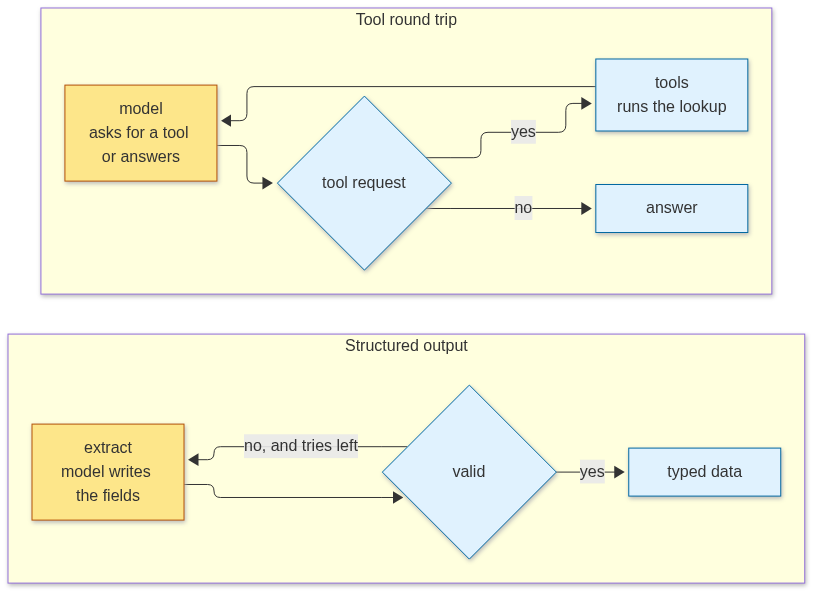

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph S["Structured output"]
    E["extract<br/>model writes the fields"] --> V{"valid"}
    V -->|no, and tries left| E
    V -->|yes| D["typed data"]
  end
  subgraph R["Tool round trip"]
    M["model<br/>asks for a tool or answers"] --> Q{"tool request"}
    Q -->|yes| T["tools<br/>runs the lookup"]
    T --> M
    Q -->|no| A["answer"]
  end
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class E,M model
  class V,Q,T,D,A code
""")

## Step by step
**Step 1 · setup (one model for the lesson).** The key is read from `.env`, never typed here. `llm_replay` saves the answers the
first time, so later runs need no key. `get_llm()` is the course's model setup (`llm_setup.py`, Gemini on Vertex AI).

In [2]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("04_structured-output-and-tools")

import json
from typing import Literal
from typing_extensions import TypedDict
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, ConfigDict, Field, ValidationError
from llm_setup import get_llm  # course helper: the shared model setup (Gemini on Vertex AI)
from graph_view import show_graph  # course helper: draws a compiled graph

llm = get_llm()
ORDERS = {  # fictional rows, the same as the earlier lessons
    "1093": {"status": "in transit", "days_late": 3, "total": 45.0},
    "1003": {"status": "lost", "days_late": 9, "total": 89.5},
}

LLM mode: replay (04_structured-output-and-tools.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · a schema the graph checks (no model call yet).** `Ticket` is what the model must return. Pydantic checks each field,
and the `Literal` allows only the categories the desk handles.

In [3]:
class Ticket(BaseModel):
    order_id: str = Field(description="The order number, four digits.", pattern=r"^\d{4}$")
    issue: Literal["not_arrived", "damaged", "wrong_item", "other"]
    refund_requested: bool

The `extract` node asks the model for a `Ticket`. With `include_raw=True` the library does not raise when the reply does not
fit: it returns the parse error in `parsing_error`, and `extract` puts its first line in `state["error"]` for the retry.

In [4]:
class ExtractState(TypedDict):
    message: str
    ticket: dict
    error: str
    tries: int


extractor = llm.with_structured_output(Ticket, include_raw=True)


def first_line(error: Exception) -> str:
    return f"{type(error).__name__}: {str(error).splitlines()[0]}"


def extract(state: ExtractState) -> dict:
    hint = f"\nThe last answer was refused: {state['error']}. Fix it." if state["error"] else ""
    reply = extractor.invoke(f"Read the customer message and fill the fields.{hint}\nMessage: {state['message']}")
    tries = state["tries"] + 1  # call 1 or a retry
    if reply["parsed"] is None:  # the reply did not fit Ticket: keep the error for the retry
        return {"ticket": {}, "tries": tries, "error": first_line(reply["parsing_error"])}
    return {"ticket": reply["parsed"].model_dump(), "tries": tries, "error": ""}

The `check` node validates the ticket again with `Ticket`, so the stored data is checked by code, not by trust. `route_check`
is the conditional edge: no error ends the graph; an error goes back to `extract` while fewer than three tries have run.

In [5]:
def check(state: ExtractState) -> dict:
    if state["error"]:  # the reply did not parse: extract already wrote the error
        return {}
    try:
        Ticket.model_validate(state["ticket"])
        return {"error": ""}
    except ValidationError as e:  # one line per failing field, joined into one message
        return {"error": "; ".join(f"{x['loc'][0]} {x['msg']}" for x in e.errors())}


def route_check(state: ExtractState) -> Literal["extract", "__end__"]:
    if not state["error"]:
        return END
    return "extract" if state["tries"] < 3 else END  # the limit: three tries, then stop

Now the graph. The edges are the only wiring: `extract` to `check`, then the conditional edge back or out.

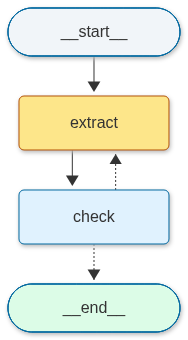

In [6]:
g = StateGraph(ExtractState)
g.add_node("extract", extract)
g.add_node("check", check)
g.add_edge(START, "extract").add_edge("extract", "check")
g.add_conditional_edges("check", route_check, {"extract": "extract", END: END})
extract_app = g.compile()
show_graph(extract_app, model_nodes=("extract",))

**Retry path, no model call.** A ticket with order_id "12" (two digits, the pattern wants four) is checked by hand. `check`
writes the error, and `route_check` sends the work back to `extract` while tries are left. At the limit it ends.

In [7]:
bad = {"order_id": "12", "issue": "damaged", "refund_requested": False}
state = {"message": "", "ticket": bad, "error": "", "tries": 1}
state |= check(state)
print("error:", state["error"])
print("route after try 1:", route_check(state))
state["tries"] = 3
print("route after try 3:", route_check(state))

error: order_id String should match pattern '^\d{4}$'
route after try 1: extract
route after try 3: __end__


**Step 3 · run the structured graph (1 model call, more only if a check fails).** The customer's message holds the facts.
The result is a dict the code can use directly, with no string parsing. If the reply failed, the graph would have gone round
the retry path shown above.

In [8]:
MESSAGE = "Order 1003 never arrived and I want my money back."
out = extract_app.invoke({"message": MESSAGE, "ticket": {}, "error": "", "tries": 0})
print("ticket:", out["ticket"], "| tries:", out["tries"], "| check:", out["error"] or "passed")

ticket: {'order_id': '1003', 'issue': 'not_arrived', 'refund_requested': True} | tries: 1 | check: passed


**Step 4 · the tool round trip, in a graph (2 model calls).** `lookup_order` is a **tool**: a function with a name, a
description and typed arguments, which the library turns into the schema the model sees. The `OrderQuery` class is that
schema for the arguments.

In [9]:
class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")  # a key the schema does not name is refused
    order_id: str = Field(description="The order number the customer wrote, digits only, such as 1003.")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one order: its status, days late and total. Use it when the customer gives an order number."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}", "next_step": "Ask for the number in the email."})

An unknown order such as 9999 is **not** a schema refusal. The tool returns its error dict as a normal result, so the model
can read it and ask the customer again. A schema refusal is different: an argument the schema does not name raises before
the tool runs (see Common mistakes).

In [10]:
print(lookup_order.invoke({"order_id": "9999"}))

{'error': 'no order 9999', 'next_step': 'Ask for the number in the email.'}


The model is bound to the tool, and the `model` node calls it. The model never runs anything; the graph does.

In [11]:
model_with_tools = llm.bind_tools([lookup_order])


def model(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke(state["messages"])]}

The graph is a cycle: the model asks for a tool, the `ToolNode` runs it, and the model reads the result. `tools_condition`
is the edge that sends a tool request to `tools` and a plain answer to the end.

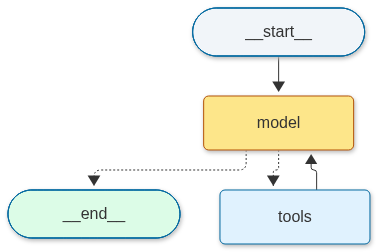

In [12]:
g2 = StateGraph(MessagesState)
g2.add_node("model", model)
g2.add_node("tools", ToolNode([lookup_order]))
g2.add_edge(START, "model")
g2.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
g2.add_edge("tools", "model")
round_trip = g2.compile()
show_graph(round_trip, model_nodes=("model",))

Run the round trip. `recursion_limit=8` in the config stops a loop that never ends: the graph raises an error after eight
steps instead of going round forever. This run needs three steps (model, tools, model), so the limit does not bite.

In [13]:
final = round_trip.invoke(
    {"messages": [HumanMessage(content=MESSAGE)]},
    config={"recursion_limit": 8},
)
for m in final["messages"][1:]:
    for call in getattr(m, "tool_calls", []) or []:
        print("the model asks for:", call["name"], call["args"], "· id:", call["id"])
    if m.type == "tool":
        print("the graph returns:", m.content)
print("answer:", final["messages"][-1].text)
llm_replay.stop()  # the last model call of this lesson

the model asks for: lookup_order {'order_id': '1003'} · id: call_1292623
the graph returns: {"status": "lost", "days_late": 9, "total": 89.5}
answer: I am very sorry to hear that your order 1003 has not arrived. I have checked the status, and it appears the package is marked as lost.

Since it is 9 days late and confirmed lost, I can certainly help you with a refund of $89.50. Would you like me to process that refund to your original payment method now?


## Under the hood
Each vendor sends a tool call in its own shape. The library turns all three into the same `tool_calls` list above, and the
result into a `ToolMessage` that carries the id. The table lists how the library hides the three vendor formats, so you know
what it hides when you read a raw response.

| Vendor | The model asks with | You send the result back as |
|---|---|---|
| Gemini | a `function_call` part | a `function_response` part, matched by name and order |
| Claude | a `tool_use` block with an `id` | a `tool_result` block that repeats the `tool_use_id` |
| OpenAI Responses | a `function_call` item with a `call_id` | a `function_call_output` item with the same `call_id` |

The `id` in the list above is what ties a result to its request. You never write these shapes by hand; the library does it.

## At work
- Teams parse model output into typed objects at the edge and refuse what does not match. The schema is the contract between
  the model and the database → lesson 32 (reliability) for retries with limits.
- A tool result is the only source of a fact the agent states. Teams make the tool return the real value, and let the model
  only choose which tool to call → lesson 06 (tools that work).
- A ticket that fails the schema three times goes to a person, not to the database → lesson 13 (approval gate).

## What just happened
- The retry path printed one error for order_id "12", sent the work back at try 1 (`extract`), and ended at try 3 (`__end__`).
- The check passed the model's Ticket for order 1003 on its first try (tries: 1), so no retry ran.
- The unknown order 9999 came back as an error dict (`no order 9999`), a normal result the model can read.
- The model's own lookup of order 1003 returned "lost, 9 days late", and the model wrote the refund offer from it.

## Common mistakes
1. **Trusting the model's fields without a check.** The schema check is what makes the output safe to store. Keep it, even
   when the model usually passes. The cell below shows what the check reports for order_id "12" and for an issue that is not
   one of the four categories.
2. **A retry with no limit.** Without a cap, a model that keeps failing keeps billing. The graph above stops after three tries.
3. **Passing a tool argument the schema does not name.** The schema refuses it before the tool runs. The cell below shows the
   refusal, with no model call.

In [14]:
try:
    Ticket.model_validate({"order_id": "12", "issue": "refund", "refund_requested": "yes"})
except ValidationError as error:  # print each failing field's type and message; a traceback shows file paths on this machine
    for line in error.errors():
        print(line["type"], "-", line["msg"])

string_pattern_mismatch - String should match pattern '^\d{4}$'
literal_error - Input should be 'not_arrived', 'damaged', 'wrong_item' or 'other'


A tool argument the schema does not name is refused the same way: the error is raised before the tool runs, so the
order lookup is never reached.

In [15]:
try:
    lookup_order.invoke({"order_id": "1003", "days": 9})  # `days` is not an argument of the tool
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

ValidationError - 1 validation error for OrderQuery


## Try it
Call `lookup_order` with `order_id` "99", which is not a desk order, and read the error dict it returns. Then write
`reply_for(result)`: it returns the `next_step` text when the result has an `error`, and otherwise a sentence with the
order's status and days late. Test it on the "99" result and on order "1093". No model call is needed.

In [16]:
result = lookup_order.invoke({"order_id": "99"})  # a tool error comes back as a normal result
print(result)

{'error': 'no order 99', 'next_step': 'Ask for the number in the email.'}


**Your turn.** Write `reply_for` in the cell below, then compare with the answer.

In [17]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [18]:
def reply_for(result: dict) -> str:
    if "error" in result:
        return result["next_step"]
    return f"Your order is {result['status']}, {result['days_late']} days late."


print(reply_for(lookup_order.invoke({"order_id": "99"})))
print(reply_for(lookup_order.invoke({"order_id": "1093"})))

Ask for the number in the email.
Your order is in transit, 3 days late.


## Key terms
- **tool** — a function the model may ask to run; the graph runs it and the model never does.
- **schema** — the typed description (field types, patterns, allowed values) that a reply must match before the code uses it.
- **tool message** (`ToolMessage`) — the message that carries a tool's result back to the model, with the id of the request it answers.
- **ToolNode** — the LangGraph node that runs the tool calls the model asked for and returns one tool message per call.
- **structured output** — a model reply that is returned as a checked object (here, a `Ticket`), not as free text.
- **recursion_limit** — the config cap on graph steps; past it, the graph stops with an error instead of looping forever.

## Recap
- A structured reply is checked against a schema; a failed check goes back to the model with the error, up to a limit.
- A tool is a function the model may request. The graph runs it and returns the result with its id.
- The round trip is a cycle with two model calls for one lookup: the request, then the answer.
- The library hides the three vendor formats; the table shows what it hides.

**Interview:** "Walk me through what the model returns when it wants a tool, and what your code sends back." Strong answer:
"It returns a request with a name, arguments and an id. The graph validates the arguments, runs the tool, and returns the
result with the same id."